# Compare the effect of different scalers on data with outliers: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/preprocessing/plot_all_scaling.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/preprocessing/plot_all_scaling.html)).

**Scenario:** two features with a long tail and a few very large outliers are transformed by every scaler and
transformer of the example: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`, `RobustScaler(quantile_range=(25, 75))`,
`PowerTransformer` (Yeo-Johnson and Box-Cox), `QuantileTransformer` (uniform and normal outputs, `random_state=42`)
and `Normalizer`; the target is rescaled with `minmax_scale`.

**Adaptations:**
- **Data substitution.** The example downloads the California housing dataset (`fetch_california_housing`); this
  notebook does not download data. It generates 20,640 rows (the dataset's size) with the same two-feature
  character: `MedInc`-like lognormal incomes (long tail) and `AveOccup`-like occupancies with 25 very large outliers,
  plus a target in [0.15, 5] that depends on income. All values are positive, so Box-Cox applies as in the original.
  Because there are more rows than `QuantileTransformer`'s `subsample=10_000`, both quantile transformers draw a
  seeded subsample (NumPy's legacy `RandomState(42)` shuffle), which Moxie reproduces.
- The example's elaborate scatter-plus-marginal-histogram figures are replaced by one compact grid of scatter plots
  per side (dpi 60), plus a table of learned attributes. The transforms themselves are identical.
- Beyond the example, learned attributes (`mean_`, `scale_`, `data_min_`, `max_abs_`, `center_`, `lambdas_`,
  `quantiles_`) and `get_feature_names_out()` are compared.

**Determinism:** deterministic (fixed data seed, `random_state=42` for the quantile subsample, closed-form scalers).
Fitted power-transform lambdas carry the optimizer tolerance explained below.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
# The reference is the pinned scikit-learn source (an overlay of the pinned Python
# sources on the installed wheel's compiled extensions), not the installed 1.9.1 wheel.
sys.path.insert(0, str(ROOT / "families/preprocessing/tests/parity"))
import overlay
sklearn = overlay.activate()
print("reference scikit-learn", sklearn.__version__, "from", Path(sklearn.__file__).parent)
%load_ext moxie_nb
nb = moxie_nb.Session("preprocessing/plot_all_scaling")

reference scikit-learn 1.10.dev0 from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/families/preprocessing/builds/oracle/sklearn


## 1. scikit-learn (Python reference)

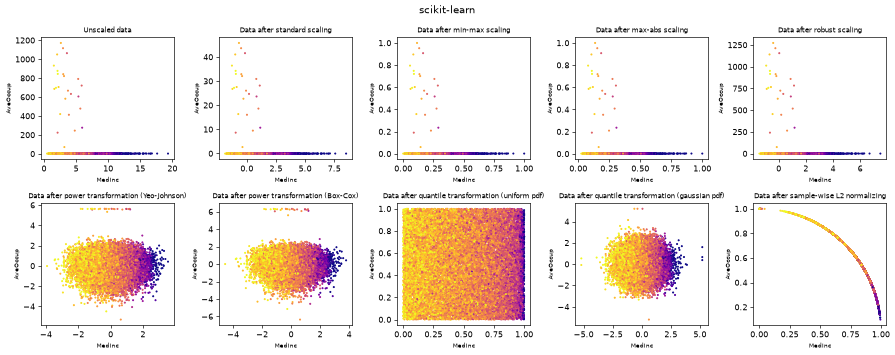

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import (
    MaxAbsScaler,
    MinMaxScaler,
    Normalizer,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
    minmax_scale,
)

# Synthetic stand-in for fetch_california_housing() (no downloads): 20,640 rows,
# a long-tailed income-like feature and an occupancy-like feature with a few huge outliers.
data_rng = np.random.RandomState(0)
n = 20_640
med_inc = np.round(data_rng.lognormal(mean=1.25, sigma=0.45, size=n), 4)
ave_occup = data_rng.lognormal(mean=1.0, sigma=0.25, size=n)
outliers = data_rng.choice(n, size=25, replace=False)
ave_occup[outliers] = data_rng.uniform(50, 1250, size=25)
X = np.c_[med_inc, ave_occup]
y_full = np.clip(0.4 * med_inc + data_rng.normal(scale=0.6, size=n), 0.15, 5.0)
features = ["MedInc", "AveOccup"]

distributions = [
    ("Unscaled data", X),
    ("Data after standard scaling", StandardScaler().fit_transform(X)),
    ("Data after min-max scaling", MinMaxScaler().fit_transform(X)),
    ("Data after max-abs scaling", MaxAbsScaler().fit_transform(X)),
    (
        "Data after robust scaling",
        RobustScaler(quantile_range=(25, 75)).fit_transform(X),
    ),
    (
        "Data after power transformation (Yeo-Johnson)",
        PowerTransformer(method="yeo-johnson").fit_transform(X),
    ),
    (
        "Data after power transformation (Box-Cox)",
        PowerTransformer(method="box-cox").fit_transform(X),
    ),
    (
        "Data after quantile transformation (uniform pdf)",
        QuantileTransformer(
            output_distribution="uniform", random_state=42
        ).fit_transform(X),
    ),
    (
        "Data after quantile transformation (gaussian pdf)",
        QuantileTransformer(
            output_distribution="normal", random_state=42
        ).fit_transform(X),
    ),
    ("Data after sample-wise L2 normalizing", Normalizer().fit_transform(X)),
]

# scale the output between 0 and 1 for the colorbar
y = minmax_scale(y_full)

# Learned attributes, refitted separately for the parity checks.
ss, mm, ma = StandardScaler().fit(X), MinMaxScaler().fit(X), MaxAbsScaler().fit(X)
rs = RobustScaler(quantile_range=(25, 75)).fit(X)
yj, bc = PowerTransformer(method="yeo-johnson").fit(X), PowerTransformer(method="box-cox").fit(X)
qu = QuantileTransformer(output_distribution="uniform", random_state=42).fit(X)

fig, axes = plt.subplots(2, 5, figsize=(15, 6), dpi=60)
for ax, (title, Xt) in zip(axes.flat, distributions):
    ax.scatter(Xt[:, 0], Xt[:, 1], s=2, c=y, cmap="plasma_r")
    ax.set_title(title, fontsize=8)
    ax.set_xlabel(features[0], fontsize=7); ax.set_ylabel(features[1], fontsize=7)
plt.suptitle("scikit-learn")
plt.tight_layout()
plt.show()
nb.share(X=X, y_full=y_full)

## 2. Moxie (native Mojo)

In [3]:
%%mojo all_scaling
from moxie.preprocessing import (
    MaxAbsScaler,
    MinMaxScaler,
    Normalizer,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
    minmax_scale,
)
from moxie_nb_io import load, save, save_strings


def main() raises:
    var X = load("X")
    var y_full = load("y_full")

    var ss = StandardScaler()
    save("standard", ss.fit_transform(X))
    save("ss_mean", ss.mean_.value())
    save("ss_scale", ss.scale_.value())
    save("ss_var", ss.var_.value())

    var mm = MinMaxScaler()
    save("minmax", mm.fit_transform(X))
    save("mm_data_min", mm.data_min_)
    save("mm_data_max", mm.data_max_)
    save("mm_scale", mm.scale_)
    save("mm_min", mm.min_)

    var ma = MaxAbsScaler()
    save("maxabs", ma.fit_transform(X))
    save("ma_max_abs", ma.max_abs_)

    var rs = RobustScaler(quantile_range=(25.0, 75.0))
    save("robust", rs.fit_transform(X))
    save("rs_center", rs.center_.value())
    save("rs_scale", rs.scale_.value())

    var yj = PowerTransformer(method="yeo-johnson")
    save("yeo_johnson", yj.fit_transform(X))
    save("yj_lambdas", yj.lambdas_)

    var bc = PowerTransformer(method="box-cox")
    save("box_cox", bc.fit_transform(X))
    save("bc_lambdas", bc.lambdas_)

    var qu = QuantileTransformer(output_distribution="uniform", random_state=42)
    save("quantile_uniform", qu.fit_transform(X))
    save("qu_quantiles", qu.quantiles_)

    var qn = QuantileTransformer(output_distribution="normal", random_state=42)
    save("quantile_normal", qn.fit_transform(X))

    var l2 = Normalizer()
    save("normalizer", l2.fit_transform(X))

    save("y", minmax_scale(y_full))
    var names: List[String] = ["MedInc", "AveOccup"]
    _ = ss.fit_named(X, names)
    save_strings("names", ss.get_feature_names_out())
    print("n_quantiles_ =", qu.n_quantiles_, "; lambdas (yj) =", yj.lambdas_)

n_quantiles_ = 1000 ; lambdas (yj) = [-0.3146 -0.9573]
1D-array  Shape: (2)  Strides: (1)  DType: f64  order: C  own data: True


## 3. Side by side and parity

Tolerances (derived in `families/preprocessing/docs/api/scalers.md` and `quantiles.md`):
- Scalers, `Normalizer`, `minmax_scale` and their learned statistics: rtol 1e-11. Means and variances are
  Float64 reductions whose summation order differs from NumPy's pairwise/SIMD loops (relative error bounded by
  about `n * eps`, far below 1e-11 for well-scaled sums of 20,640 values); extrema and percentiles are exact.
- Quantile transforms: rtol 1e-12, atol 1e-15 (operation-by-operation replay, final-bit rounding only);
  `quantiles_` exact, including the seeded 10,000-row subsample.
- `lambdas_`: rtol/atol 2e-7 (flat log-likelihood near the Brent optimum); power-transformed values rtol/atol 1e-6
  (that tolerance propagated through the transform and standardization).

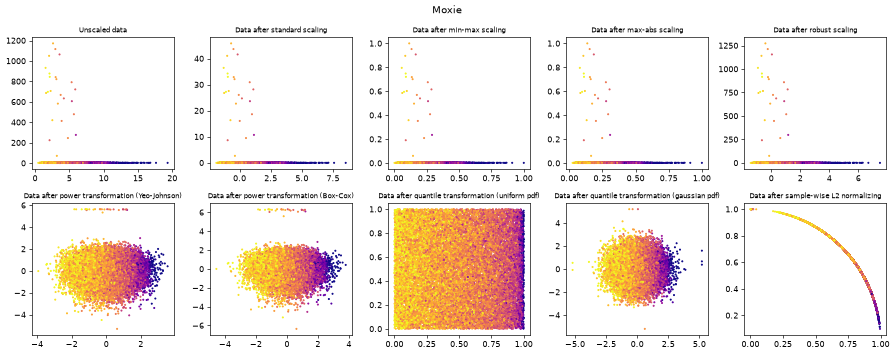

,mean_,scale_,center_,robust scale_,yj lambdas_,bc lambdas_
MedInc,3.85182,1.816185,3.474900,2.115050,-0.314727,-0.015404
AveOccup,3.61863,25.497563,2.722327,0.918416,-0.957311,-0.593931
,mean_,scale_,center_,robust scale_,yj lambdas_,bc lambdas_
MedInc,3.85182,1.816185,3.474900,2.115050,-0.314727,-0.015404
AveOccup,3.61863,25.497563,2.722327,0.918416,-0.957310,-0.593931


In [4]:
mx = nb.results["all_scaling"]
keys = [None, "standard", "minmax", "maxabs", "robust", "yeo_johnson", "box_cox",
        "quantile_uniform", "quantile_normal", "normalizer"]

fig, axes = plt.subplots(2, 5, figsize=(15, 6), dpi=60)
for ax, (title, _), key in zip(axes.flat, distributions, keys):
    Xt = X if key is None else mx[key]
    ax.scatter(Xt[:, 0], Xt[:, 1], s=2, c=mx["y"], cmap="plasma_r")
    ax.set_title(title, fontsize=8)
plt.suptitle("Moxie")
plt.tight_layout()
plt.show()

import pandas as pd
moxie_nb.side_by_side(
    sklearn=pd.DataFrame({"mean_": ss.mean_, "scale_": ss.scale_, "center_": rs.center_, "robust scale_": rs.scale_,
                          "yj lambdas_": yj.lambdas_, "bc lambdas_": bc.lambdas_}, index=features),
    moxie=pd.DataFrame({"mean_": mx["ss_mean"], "scale_": mx["ss_scale"], "center_": mx["rs_center"],
                        "robust scale_": mx["rs_scale"], "yj lambdas_": mx["yj_lambdas"],
                        "bc lambdas_": mx["bc_lambdas"]}, index=features))

closed_form = "Float64 reductions; summation order differs (error ~ n*eps)"
for (title, Xt), key in zip(distributions[1:], keys[1:]):
    if key in ("yeo_johnson", "box_cox"):
        nb.compare(title, Xt, mx[key], rtol=1e-6, atol=1e-6, reason="lambda tolerance propagated")
    elif key.startswith("quantile"):
        nb.compare(title, Xt, mx[key], rtol=1e-12, atol=1e-15, reason="interp/ndtri replayed; final-bit rounding")
    else:
        nb.compare(title, Xt, mx[key], rtol=1e-11, reason=closed_form)
nb.compare("minmax_scale(y_full)", y, mx["y"], rtol=1e-11, reason="min/max exact; one subtraction and division")
for name, sk_value, key in [("StandardScaler.mean_", ss.mean_, "ss_mean"), ("StandardScaler.var_", ss.var_, "ss_var"),
                            ("StandardScaler.scale_", ss.scale_, "ss_scale"),
                            ("RobustScaler.scale_", rs.scale_, "rs_scale")]:
    nb.compare(name, sk_value, mx[key], rtol=1e-11, reason=closed_form)
for name, sk_value, key in [("MinMaxScaler.data_min_", mm.data_min_, "mm_data_min"),
                            ("MinMaxScaler.data_max_", mm.data_max_, "mm_data_max"),
                            ("MinMaxScaler.scale_", mm.scale_, "mm_scale"), ("MinMaxScaler.min_", mm.min_, "mm_min"),
                            ("MaxAbsScaler.max_abs_", ma.max_abs_, "ma_max_abs"),
                            ("RobustScaler.center_", rs.center_, "rs_center"),
                            ("QuantileTransformer.quantiles_ (seeded subsample)", qu.quantiles_, "qu_quantiles")]:
    nb.compare(name, sk_value, mx[key], exact=True)
nb.compare("PowerTransformer(yeo-johnson).lambdas_", yj.lambdas_, mx["yj_lambdas"], rtol=2e-7, atol=2e-7,
           reason="Brent stops within xtol on a flat log-likelihood")
nb.compare("PowerTransformer(box-cox).lambdas_", bc.lambdas_, mx["bc_lambdas"], rtol=2e-7, atol=2e-7,
           reason="Brent stops within xtol on a flat log-likelihood")
nb.compare("StandardScaler.get_feature_names_out (named fit)",
           StandardScaler().fit(pd.DataFrame(X, columns=features)).get_feature_names_out(), mx["names"], exact=True)
nb.note("fetch_california_housing", "ADAPTED", "no downloads: synthetic data with the same size and two-feature character")

In [5]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Data after standard scaling,PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-11, atol=0",,Float64 reductions; summation order differs (error ~ n*eps)
Data after min-max scaling,PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-11, atol=0",,Float64 reductions; summation order differs (error ~ n*eps)
Data after max-abs scaling,PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-11, atol=0",,Float64 reductions; summation order differs (error ~ n*eps)
Data after robust scaling,PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-11, atol=0",,Float64 reductions; summation order differs (error ~ n*eps)
Data after power transformation (Yeo-Johnson),PASS,"(20640, 2)","(20640, 2)",2.38e-07,8.05e-05,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated
Data after power transformation (Box-Cox),PASS,"(20640, 2)","(20640, 2)",1.25e-07,0.000122,"rtol=1e-06, atol=1e-06",,lambda tolerance propagated
Data after quantile transformation (uniform pdf),PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-12, atol=1e-15",,interp/ndtri replayed; final-bit rounding
Data after quantile transformation (gaussian pdf),PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-12, atol=1e-15",,interp/ndtri replayed; final-bit rounding
Data after sample-wise L2 normalizing,PASS,"(20640, 2)","(20640, 2)",0,0,"rtol=1e-11, atol=0",,Float64 reductions; summation order differs (error ~ n*eps)
minmax_scale(y_full),PASS,"(20640,)","(20640,)",0,0,"rtol=1e-11, atol=0",,min/max exact; one subtraction and division
